Use SHAP values to interpret model predictions by generating global and local explanations, identifying the most influential features for different classes, and comparing SHAP results across multiple models for deeper interpretability.

In [1]:
import joblib
import os
import shap
import numpy as np

c:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
save_folder = "task31_saved_files"

saved_models = "saved_models"
preprocessor = joblib.load(os.path.join(save_folder, "preprocessor.pkl"))
feature_config = joblib.load(os.path.join(save_folder, "feature_config.pkl"))
x_test = joblib.load(os.path.join(save_folder, "x_test.pkl"))
y_test = joblib.load(os.path.join(save_folder, "y_test.pkl"))
x_train = joblib.load(os.path.join(save_folder, "x_train.pkl"))
y_train = joblib.load(os.path.join(save_folder, "y_train.pkl"))

x_train_processed = preprocessor.transform(x_train)
x_test_processed = preprocessor.transform(x_test)

baseline_xgb_model = joblib.load(os.path.join(saved_models, "baseline_xgb_model.pkl"))

tuned_xgb_model = joblib.load(os.path.join(saved_models, "tuned_xgb_model.pkl"))

print("All saved files loaded successfully!")

All saved files loaded successfully!


In [3]:
feature_names = preprocessor.get_feature_names_out()

print("Training Shape:", x_train_processed.shape)
print("Testing Shape:", x_test_processed.shape)

print("Number of Features:", len(feature_names))
print("Feature Names Sample:")
print(feature_names[:20])

print("\nTarget Distribution:")
print(y_test.value_counts())

Training Shape: (18786, 3049)
Testing Shape: (4697, 3049)
Number of Features: 3049
Feature Names Sample:
['num__customer_age' 'num__rating' 'num__vader_negative'
 'num__vader_neutral' 'num__vader_positive' 'num__vader_compound'
 'num__vader_sentiment_score' 'cat__category_General'
 'cat__category_General Petite' 'cat__category_Initmates'
 'cat__subcategory1_Bottoms' 'cat__subcategory1_Dresses'
 'cat__subcategory1_Intimate' 'cat__subcategory1_Jackets'
 'cat__subcategory1_Tops' 'cat__subcategory1_Trend'
 'cat__subcategory2_Blouses' 'cat__subcategory2_Casual bottoms'
 'cat__subcategory2_Chemises' 'cat__subcategory2_Dresses']

Target Distribution:
recommend_flag
1    3863
0     834
Name: count, dtype: int64


In [4]:
baseline_model = joblib.load('saved_models/baseline_xgb_model.pkl')

tuned_model = joblib.load('saved_models/tuned_xgb_model.pkl')

bayesian_model = joblib.load('saved_models/bayesian_xgb_model.pkl')

models = {
    "Baseline XGBoost": baseline_model,
    "Tuned XGBoost": tuned_model,
    "Bayesian XGBoost": bayesian_model
}

for name, model in models.items():
    print(f"\n{name}")
    print("Model: ", type(model))
    print("features: ", model.n_features_in_)
    print("Predictions: ", model.predict(x_test_processed)[:5])


Baseline XGBoost
Model:  <class 'xgboost.sklearn.XGBClassifier'>
features:  3049
Predictions:  [1 1 1 1 1]

Tuned XGBoost
Model:  <class 'xgboost.sklearn.XGBClassifier'>
features:  3049
Predictions:  [1 1 1 1 1]

Bayesian XGBoost
Model:  <class 'xgboost.sklearn.XGBClassifier'>
features:  3049
Predictions:  [1 1 1 1 1]


Calculate SHAP values for all 3 models

In [5]:
rng = np.random.default_rng(42)

class_0_indices = np.where(np.asarray(y_test) == 0)[0]
class_1_indices = np.where(np.asarray(y_test) == 1)[0]

selected_0 = rng.choice(class_0_indices, 100, replace=False)
selected_1 = rng.choice(class_1_indices, 100, replace=False)

selected_indices = np.concatenate([selected_0, selected_1])

x_sample = x_test_processed[selected_indices]

if hasattr(x_sample, "toarray"):
    x_sample = x_sample.toarray()

y_sample = np.asarray(y_test)[selected_indices]

print("Sample Shape:", x_sample.shape)
print("\nClass Distribution:")
print(pd.Series(y_sample).value_counts())

Sample Shape: (200, 3049)

Class Distribution:
0    100
1    100
Name: count, dtype: int64


In [6]:
shap_explanation = {}

for name, model in models.items():

    print(f"\nCalculating SHAP values for {name}...")

    explainer = shap.TreeExplainer(model)
    explanation = explainer(x_sample)
    shap_explanation[name] = explanation
    print("SHAP Shape:", explanation.values.shape)



Calculating SHAP values for Baseline XGBoost...
SHAP Shape: (200, 3049)

Calculating SHAP values for Tuned XGBoost...
SHAP Shape: (200, 3049)

Calculating SHAP values for Bayesian XGBoost...
SHAP Shape: (200, 3049)


Global SHAP Summary Plots


Baseline XGBoost - SHAP Summary Plot


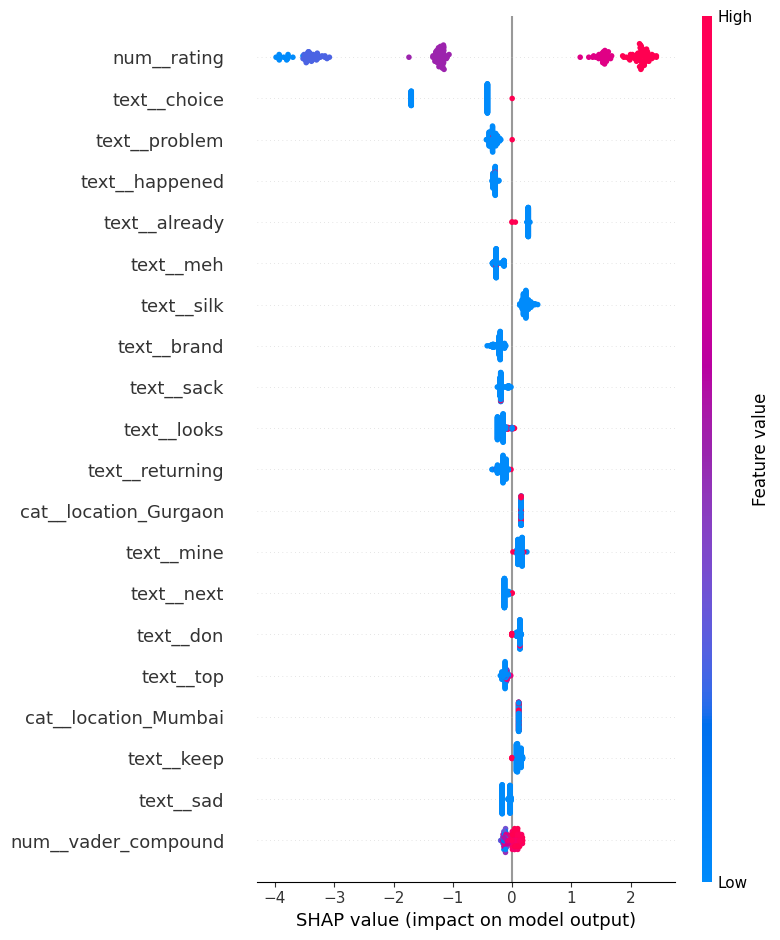


Tuned XGBoost - SHAP Summary Plot


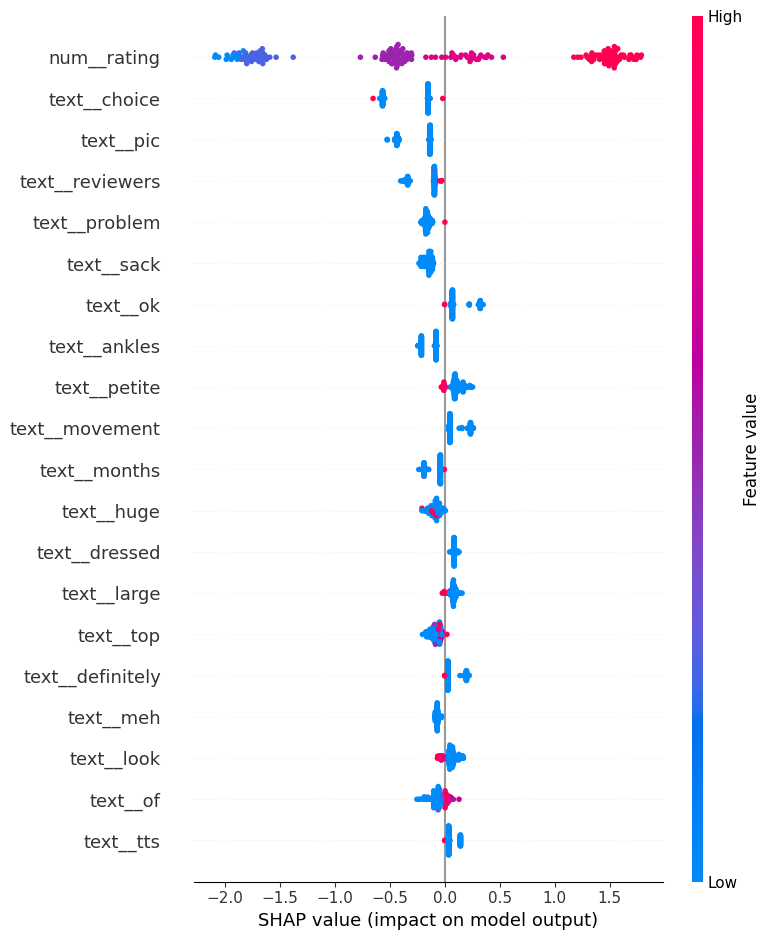


Bayesian XGBoost - SHAP Summary Plot


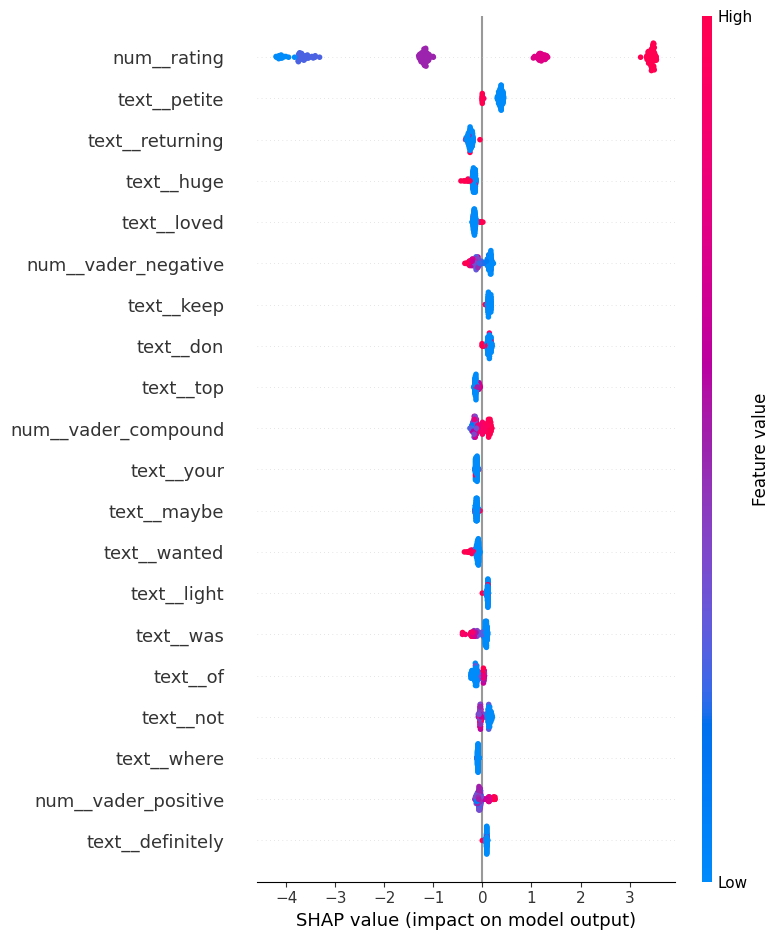

In [7]:
for name, explanation in shap_explanation.items():

    print(f"\n{name} - SHAP Summary Plot")

    shap.summary_plot(
    explanation.values,
    x_sample,
    feature_names=feature_names,
    max_display=20,
    show=True
    )

Compare Global Feature Importance Across Models

In [8]:
importance_results = []

for model_name, explanation in shap_explanation.items():
    mean_shap = np.abs(explanation.values).mean(axis=0)

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Mean SHAP Value": mean_shap
    }).sort_values(by="Mean SHAP Value", ascending=False)

    importance_df['Model'] = model_name
    importance_results.append(importance_df.head(10))

comparison_df = pd.concat(importance_results, ignore_index=True)

print(comparison_df[
    ["Model", "Feature", "Mean SHAP Value"]
].to_string(index=False))

           Model             Feature  Mean SHAP Value
Baseline XGBoost         num__rating         2.161148
Baseline XGBoost        text__choice         0.838206
Baseline XGBoost       text__problem         0.313573
Baseline XGBoost      text__happened         0.296018
Baseline XGBoost       text__already         0.268889
Baseline XGBoost           text__meh         0.254393
Baseline XGBoost          text__silk         0.237844
Baseline XGBoost         text__brand         0.224351
Baseline XGBoost          text__sack         0.179391
Baseline XGBoost         text__looks         0.169426
   Tuned XGBoost         num__rating         1.101895
   Tuned XGBoost        text__choice         0.287316
   Tuned XGBoost           text__pic         0.234380
   Tuned XGBoost     text__reviewers         0.170534
   Tuned XGBoost       text__problem         0.159926
   Tuned XGBoost          text__sack         0.149980
   Tuned XGBoost            text__ok         0.130357
   Tuned XGBoost        text

Class-wise SHAP Analysis

In [9]:
classwise_res = []

for model_name, explanation in shap_explanation.items():
    shap_values = explanation.values

    for class_label in [0, 1]:
        class_indices = np.where(y_sample == class_label)[0]
        class_shap = shap_values[class_indices]

        mean_importance = np.abs(class_shap).mean(axis=0)

        class_df = pd.DataFrame({
            "Feature": feature_names,
            "Mean SHAP": mean_importance,
        })

        class_df = class_df.sort_values(by="Mean SHAP", ascending=False).head(10)

        class_df['Model'] = model_name
        class_df['Class'] = class_label

        classwise_res.append(class_df)

    classwise_comparison = pd.concat(classwise_res, ignore_index=True)

    print(classwise_comparison.to_string(index=False))

        Feature  Mean SHAP            Model  Class
    num__rating   2.386892 Baseline XGBoost      0
   text__choice   0.412193 Baseline XGBoost      0
  text__problem   0.318733 Baseline XGBoost      0
 text__happened   0.286959 Baseline XGBoost      0
  text__already   0.267196 Baseline XGBoost      0
     text__silk   0.259156 Baseline XGBoost      0
      text__meh   0.255397 Baseline XGBoost      0
    text__brand   0.232691 Baseline XGBoost      0
     text__sack   0.176542 Baseline XGBoost      0
text__returning   0.175441 Baseline XGBoost      0
    num__rating   1.935403 Baseline XGBoost      1
   text__choice   1.264219 Baseline XGBoost      1
  text__problem   0.308413 Baseline XGBoost      1
 text__happened   0.305078 Baseline XGBoost      1
  text__already   0.270581 Baseline XGBoost      1
      text__meh   0.253389 Baseline XGBoost      1
     text__silk   0.216532 Baseline XGBoost      1
    text__brand   0.216010 Baseline XGBoost      1
     text__sack   0.182240 Base

Local SHAP Explanation – Waterfall Plots

In [10]:
# Predictions on balanced sample
bayesian_predictions = bayesian_model.predict(x_sample)

# Find correctly predicted observations
class_0_correct = np.where((y_sample == 0) & (bayesian_predictions == 0))[0]

class_1_correct = np.where((y_sample == 1) & (bayesian_predictions == 1))[0]

print("Correct Class 0 samples:", len(class_0_correct))
print("Correct Class 1 samples:", len(class_1_correct))

# Select one observation from each class
idx_0 = class_0_correct[0]
idx_1 = class_1_correct[0]

print("\nClass 0 - Actual: ", y_sample[idx_0], "Predicted: ", bayesian_predictions[idx_0])
print("Class 1 - Actual: ", y_sample[idx_1], "Predicted: ", bayesian_predictions[idx_1])

Correct Class 0 samples: 76
Correct Class 1 samples: 98

Class 0 - Actual:  0 Predicted:  0
Class 1 - Actual:  1 Predicted:  1


In [11]:
import matplotlib.pyplot as plt

Local SHAP Explanation - Class 0


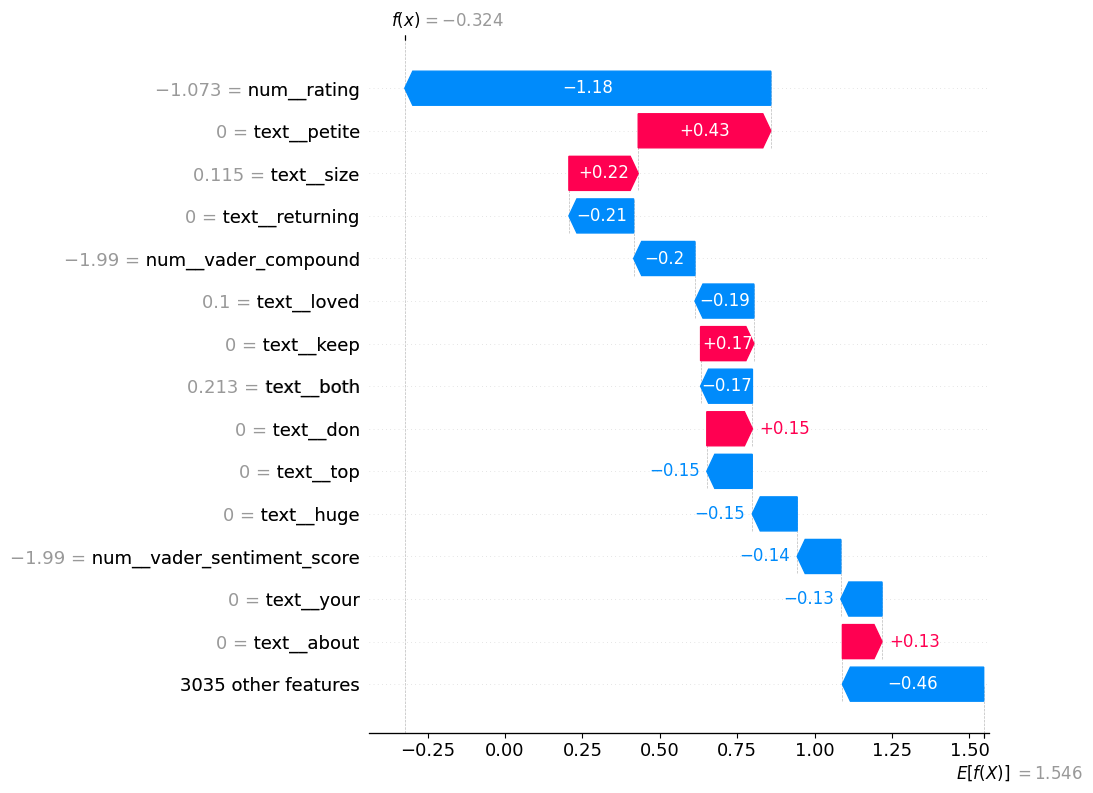

Local SHAP Explanation - Class 1


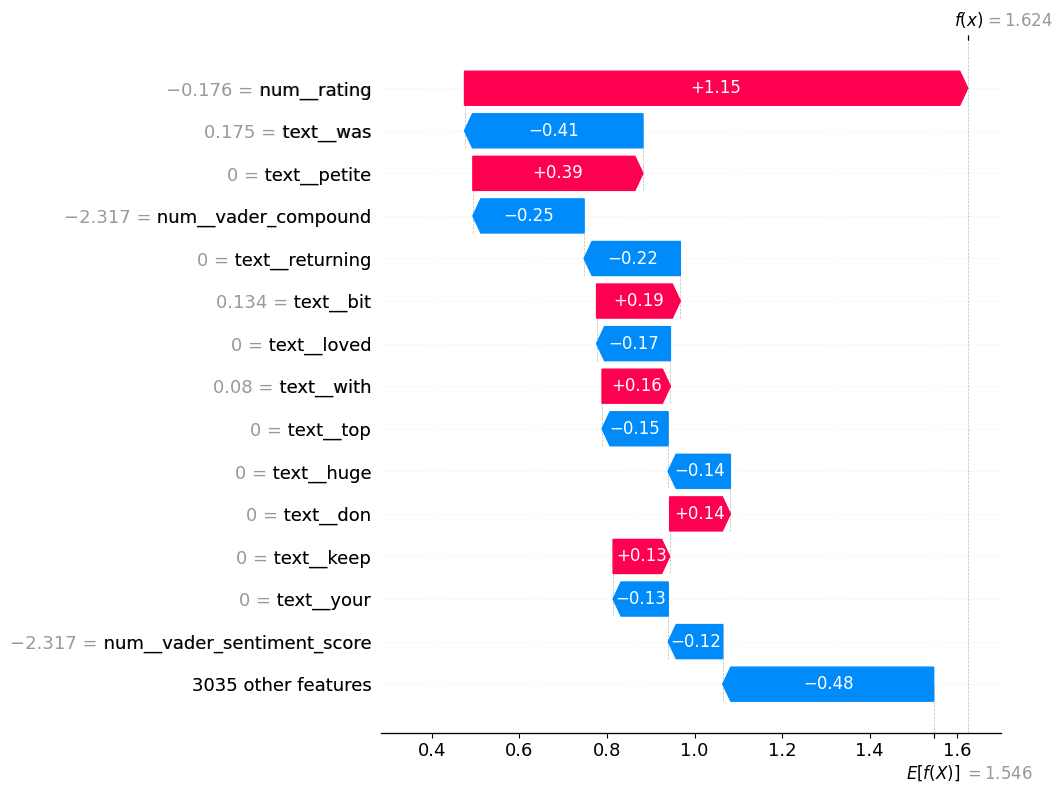

In [18]:
# Create SHAP Explanation with actual feature names
bayesian_explanation = shap_explanation["Bayesian XGBoost"]

explanation_with_names = shap.Explanation(
    values=bayesian_explanation.values,
    base_values=bayesian_explanation.base_values,
    data=x_sample,
    feature_names=list(feature_names)
)

print("Local SHAP Explanation - Class 0")

shap.plots.waterfall(explanation_with_names[idx_0], max_display=15)
plt.show()

print("Local SHAP Explanation - Class 1")

shap.plots.waterfall(explanation_with_names[idx_1], max_display=15)
plt.show()

Compare Local SHAP Across Three Models

In [20]:
for name, explanation in shap_explanation.items():
    print("\n", "-" * 60)
    print(name)
    print("-" * 60)

    for label, idx in [
        ("class 0", idx_0),
        ("class 1", idx_1)
    ]:
        values = explanation.values[idx]

        top_indices = np.argsort(np.abs(values))[-10:][::-1]

        print(f"\n{label} - Top 10 Features")

        for i in top_indices:
            print(f"{feature_names[i]} : {values[i]:.4f}")

        print("Base value:", explanation.base_values[idx])
        print("Final raw output:", explanation.base_values[idx] + values.sum())


 ------------------------------------------------------------
Baseline XGBoost
------------------------------------------------------------

class 0 - Top 10 Features
num__rating : -1.2598
text__choice : -0.4163
text__meh : -0.3304
text__happened : -0.2840
text__silk : 0.2761
text__already : 0.2731
text__returning : -0.2475
text__problem : -0.2474
text__brand : -0.2233
text__keep : 0.1723
Base value: 1.622912
Final raw output: -0.8376707

class 1 - Top 10 Features
num__rating : 1.2941
text__choice : -0.4163
text__was : -0.3313
text__problem : -0.3293
text__happened : -0.2839
text__already : 0.2731
text__meh : -0.2683
text__looks : -0.2463
text__sack : -0.2038
text__brand : -0.2001
Base value: 1.622912
Final raw output: 0.8559277

 ------------------------------------------------------------
Tuned XGBoost
------------------------------------------------------------

class 0 - Top 10 Features
num__rating : -0.3727
text__sack : -0.2176
text__top : -0.1644
text__problem : -0.1561
text__ch

### Conclusion

SHAP (SHapley Additive exPlanations) was used to interpret the predictions of three XGBoost classification models: Baseline XGBoost, Tuned XGBoost, and Bayesian XGBoost.

Global SHAP analysis identified `num__rating` as the most influential feature across all three models. Text-based features such as `text__choice`, `text__problem`, `text__petite`, and `text__returning` also contributed significantly to model predictions. The importance of these features varied across models, indicating differences in how each model learned patterns from the dataset.

Class-wise SHAP analysis was performed separately for Class 0 and Class 1 using a balanced sample of 100 observations per class. The results showed that customer rating was the most influential feature for both classes across all three models. However, the relative importance of text and sentiment-related features differed between models and classes.

Local SHAP explanations were generated using waterfall plots for one correctly classified observation from each class by the Bayesian XGBoost model. These plots demonstrated how individual feature contributions shifted model outputs from their respective baseline values towards the final predictions.

Finally, local explanations were compared across all three models using the same two observations. Baseline and Bayesian XGBoost correctly classified both selected observations, whereas Tuned XGBoost misclassified the selected Class 0 observation. This comparison demonstrated that different models can rely on different feature contributions and produce different predictions for the same observation.

Overall, SHAP provided global, class-wise, and local interpretability, helping explain model behaviour beyond conventional performance metrics. The analysis also highlighted the dominant influence of customer rating, which should be evaluated carefully to ensure it is available at the actual prediction stage and does not introduce target leakage.

Thus, the task successfully demonstrated model interpretability and comparison using SHAP values across multiple XGBoost models.